In [142]:

import os
import csv
import torch
import pandas as pd

from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset ,DataLoader,Subset
from torchvision.io import read_image
from torchvision import transforms
from sklearn.model_selection import train_test_split

from pathlib import Path

In [143]:
#DEFINING CONSTATNTS

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATASET_DIR = PROJECT_DIR / "data" / "raw"
ANNOTATIONS = PROJECT_DIR / "data" / "labels.csv"

IMG_SIZE = (300, 300)
BATCH_SIZE = 32
EPOCHS = 15
NUM_CLASSES = 36

images_path = Path("notebooks/dataset")
annotations = Path("data/labels.csv")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [144]:
class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
        self.img_labels = pd.read_csv(annotations_file)
        self.img_dir = Path(img_dir)
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):
        img_path = self.img_dir / self.img_labels.iloc[idx]["image_path"]

        image = read_image(str(img_path))
        label = int(self.img_labels.iloc[idx]["label"])

        if self.transform:
            image = self.transform(image)

        if self.target_transform:
            label = self.target_transform(label)

        return image, label

In [145]:
class PadToSquare:
    """Pad the shorter dimension to make image square, preserving aspect ratio."""
    def __init__(self, fill=0):
        self.fill = fill

    def __call__(self, img):
        # img is a tensor: (C, H, W)
        h, w = img.shape[-2:]
        if w == h:
            return img
        max_dim = max(w, h)
        padding = [0, 0, 0, 0]  # left, top, right, bottom
        if w < max_dim:
            diff = max_dim - w
            padding[0] = diff // 2
            padding[2] = diff - padding[0]
        elif h < max_dim:
            diff = max_dim - h
            padding[1] = diff // 2
            padding[3] = diff - padding[1]
        return transforms.functional.pad(img, padding, fill=self.fill)


transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    PadToSquare(fill=0),
    transforms.Resize(IMG_SIZE),
    transforms.ConvertImageDtype(torch.float32),
    transforms.Normalize((0.5,), (0.5,))
])

In [146]:
full_labels = pd.read_csv(ANNOTATIONS)

train_val_df, test_df = train_test_split(
    full_labels, test_size=0.2, random_state=42, stratify=full_labels['label']
)

In [147]:
train_df, val_df = train_test_split(
    train_val_df, test_size=0.2, random_state=42, stratify=train_val_df['label']
)

In [148]:
full_dataset = CustomImageDataset(
    annotations_file=ANNOTATIONS,
    img_dir=PROJECT_DIR,
    transform=transform
)


In [149]:
train_dataset = Subset(full_dataset, train_df.index.tolist())
val_dataset = Subset(full_dataset, val_df.index.tolist())
test_dataset = Subset(full_dataset, test_df.index.tolist())


In [150]:
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [151]:
print(f"Train samples: {len(train_dataset)}")
print(f"Val samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Train samples: 34560
Val samples: 8640
Test samples: 10800


In [152]:

class CNN(nn.Module):
    def __init__(self, num_classes=36):
        super().__init__()

        # Convolutional layers
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)

        # Max pooling
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Adaptive pooling
        self.adaptive_pool = nn.AdaptiveAvgPool2d((7, 7))

        # Fully connected layers
        self.fc1 = nn.Linear(64 * 7 * 7, 512)
        self.fc2 = nn.Linear(512, num_classes)

        # Dropout
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = self.adaptive_pool(x)
        x = torch.flatten(x, start_dim=1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        # Raw logits for CrossEntropyLoss
        x = self.fc2(x)

        return x


In [153]:

model = CNN(num_classes=NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
# Initialize history lists to store metrics for plotting
train_loss_history = []
val_loss_history = []
train_acc_history = []
val_acc_history = []

# Early Stopping Variables
best_val_loss = float('inf')
patience = 8         
trigger_times = 0

model = model.to(device)

for epoch in range(EPOCHS):
    # --- TRAINING PHASE ---
    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_dataloader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels.long())
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for images, labels in val_dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels.long())
            val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    # Calculate averages
    avg_train_loss = running_loss / len(train_dataloader)
    avg_val_loss = val_loss / len(val_dataloader)
    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total

    # --- SAVE METRICS TO LISTS ---
    train_loss_history.append(avg_train_loss)
    val_loss_history.append(avg_val_loss)
    train_acc_history.append(train_acc)
    val_acc_history.append(val_acc)

    print(
        f'Epoch [{epoch+1}/{EPOCHS}] | '
        f'Train Loss: {avg_train_loss:.4f} | Train Acc: {train_acc:.2f}% | '
        f'Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.2f}%'
    )

    # --- EARLY STOPPING LOGIC ---
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        trigger_times = 0
        torch.save(model.state_dict(), 'best_model.pth')
        print(f" Saved new best model (Val Loss: {best_val_loss:.4f})")
    else:
        trigger_times += 1
        print(f"  No improvement. Trigger count: {trigger_times}/{patience}")
        
    if trigger_times >= patience:
        print("Early stopping triggered! Ending training.")
        break

print("\nLoading best model weights for final testing...")
model.load_state_dict(torch.load('best_model.pth'))

Epoch [1/15] | Train Loss: 0.9028 | Train Acc: 69.95% | Val Loss: 0.2218 | Val Acc: 92.21%
 Saved new best model (Val Loss: 0.2218)


In [ ]:
model.eval()
test_correct = 0
test_total = 0

# Track accuracy per class 
class_correct = list(0. for i in range(NUM_CLASSES))
class_total = list(0. for i in range(NUM_CLASSES))

with torch.no_grad():
    for images, labels in test_dataloader:
        images, labels = images.to(device), labels.to(device)
        
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()
        
        # Per-class accuracy tracking
        c = (predicted == labels).squeeze()
        for i in range(labels.size(0)):
            label = labels[i]
            class_correct[label] += c[i].item()
            class_total[label] += 1

print(f'\n--- Final Test Results ---')
print(f'Overall Test Accuracy: {100 * test_correct / test_total:.2f}%\n')

print('Per-Class Accuracy:')
for i in range(NUM_CLASSES):
    if class_total[i] > 0:
        print(f'Class {i:02d}: {100 * class_correct[i] / class_total[i]:.2f}%')


--- Final Test Results ---
Overall Test Accuracy: 99.55%

Per-Class Accuracy:
Class 00: 92.33%
Class 01: 98.67%
Class 02: 98.67%
Class 03: 99.67%
Class 04: 99.00%
Class 05: 99.67%
Class 06: 99.00%
Class 07: 99.67%
Class 08: 98.67%
Class 09: 100.00%
Class 10: 100.00%
Class 11: 100.00%
Class 12: 100.00%
Class 13: 100.00%
Class 14: 100.00%
Class 15: 100.00%
Class 16: 100.00%
Class 17: 100.00%
Class 18: 100.00%
Class 19: 100.00%
Class 20: 100.00%
Class 21: 100.00%
Class 22: 100.00%
Class 23: 100.00%
Class 24: 98.33%
Class 25: 100.00%
Class 26: 100.00%
Class 27: 100.00%
Class 28: 100.00%
Class 29: 100.00%
Class 30: 100.00%
Class 31: 100.00%
Class 32: 100.00%
Class 33: 100.00%
Class 34: 100.00%
Class 35: 100.00%


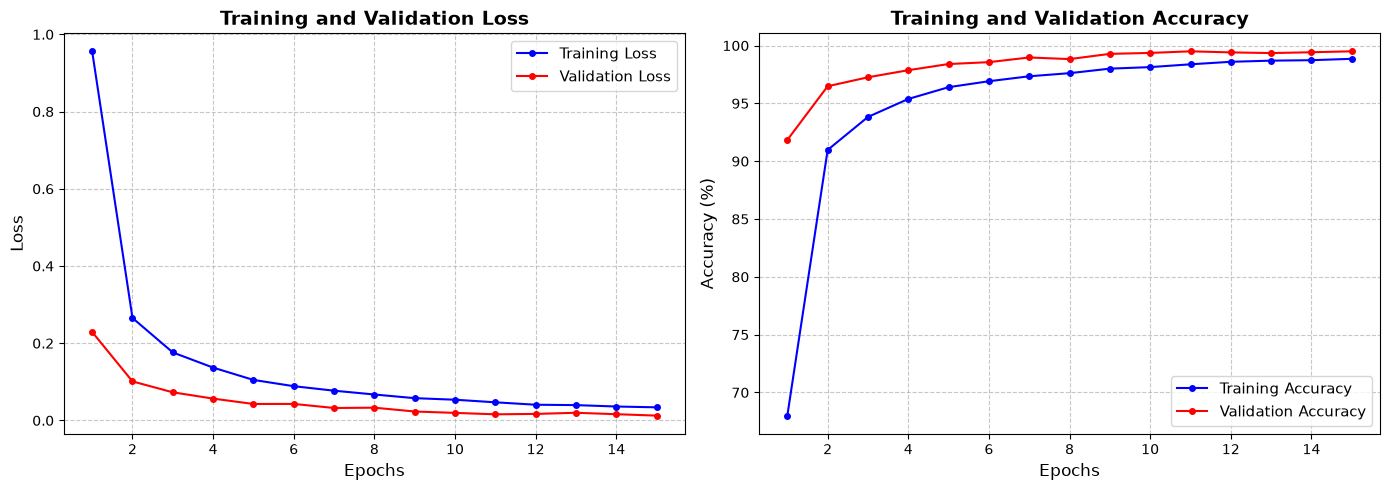

In [ ]:
import matplotlib.pyplot as plt

# Create a figure with 2 subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Generate x-axis values (Epoch numbers)
epochs_range = range(1, len(train_loss_history) + 1)

# --- Plot 1: Loss ---
ax1.plot(epochs_range, train_loss_history, 'b-o', label='Training Loss', markersize=4)
ax1.plot(epochs_range, val_loss_history, 'r-o', label='Validation Loss', markersize=4)
ax1.set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epochs', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.legend(fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.7)

# --- Plot 2: Accuracy ---
ax2.plot(epochs_range, train_acc_history, 'b-o', label='Training Accuracy', markersize=4)
ax2.plot(epochs_range, val_acc_history, 'r-o', label='Validation Accuracy', markersize=4)
ax2.set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epochs', fontsize=12)
ax2.set_ylabel('Accuracy (%)', fontsize=12)
ax2.legend(fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.7)

# Adjust layout so nothing overlaps
plt.tight_layout()

# Display the plot
plt.show()



In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path
import cv2
from PIL import Image

# Load annotations and create test split (same as training)
labels_path = PROJECT_DIR / "data" / "labels.csv"
full_labels = pd.read_csv(labels_path)

train_val_df, test_df = train_test_split(
    full_labels, test_size=0.2, random_state=42, stratify=full_labels['label']
)

# Dataset class
class CustomImageDataset(torch.utils.data.Dataset):
    def __init__(self, annotations_file, img_dir, transform=None):
        self.img_labels = pd.read_csv(annotations_file)
        self.img_dir = Path(img_dir)
        self.transform = transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):
        img_path = self.img_dir / self.img_labels.iloc[idx]["image_path"]
        image = cv2.imread(str(img_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        label = int(self.img_labels.iloc[idx]["label"])
        if self.transform:
            image = self.transform(image)
        return image, label

# CNN architecture (same as training)
class CNN(nn.Module):
    def __init__(self, num_classes=36):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((7, 7))
        self.fc1 = nn.Linear(64 * 7 * 7, 512)
        self.fc2 = nn.Linear(512, num_classes)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = self.adaptive_pool(x)
        x = torch.flatten(x, start_dim=1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# PadToSquare transform (same as training)
class PadToSquare:
    """Pad the shorter dimension to make image square, preserving aspect ratio."""
    def __init__(self, fill=0):
        self.fill = fill

    def __call__(self, img):
        if isinstance(img, Image.Image):
            w, h = img.size
        else:
            h, w = img.shape[-2:]
        if w == h:
            return img
        max_dim = max(w, h)
        padding = [0, 0, 0, 0]  # left, top, right, bottom
        if w < max_dim:
            diff = max_dim - w
            padding[0] = diff // 2
            padding[2] = diff - padding[0]
        elif h < max_dim:
            diff = max_dim - h
            padding[1] = diff // 2
            padding[3] = diff - padding[1]
        return transforms.functional.pad(img, padding, fill=self.fill)

# Transform (same as training)
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Grayscale(num_output_channels=1),
    PadToSquare(fill=0),
    transforms.Resize((300, 300)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Create test dataset and loader
test_dataset = Subset(
    CustomImageDataset(
        annotations_file=labels_path,
        img_dir=PROJECT_DIR,
        transform=transform
    ),
    test_df.index.tolist()
)

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Load trained model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN(num_classes=36).to(device)
model.load_state_dict(torch.load(PROJECT_DIR / "notebooks" / "best_model.pth", map_location=device))
model.eval()

# Run inference on test set
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Compute metrics
precision, recall, f1, support = precision_recall_fscore_support(all_labels, all_preds, average=None)
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro')
weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')

# Print overall metrics
print("=" * 60)
print("OVERALL METRICS")
print("=" * 60)
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall:    {macro_recall:.4f}")
print(f"Macro F1-Score:  {macro_f1:.4f}")
print()
print(f"Weighted Precision: {weighted_precision:.4f}")
print(f"Weighted Recall:    {weighted_recall:.4f}")
print(f"Weighted F1-Score:  {weighted_f1:.4f}")

# Per-class metrics
print("\n" + "=" * 60)
print("PER-CLASS METRICS")
print("=" * 60)
class_names = [str(i) for i in range(36)]
for i in range(36):
    print(f"Class {i:2d}: Precision={precision[i]:.4f}, Recall={recall[i]:.4f}, F1={f1[i]:.4f}, Support={support[i]}")

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot Confusion Matrix
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Count'})
plt.title('Confusion Matrix - Test Set', fontsize=16, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

# Normalized Confusion Matrix (row-wise percentages)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(14, 12))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Proportion'},
            vmin=0, vmax=1)
plt.title('Normalized Confusion Matrix (Row-wise %)', fontsize=16, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

# Per-class F1 bar plot
plt.figure(figsize=(14, 6))
bars = plt.bar(range(36), f1, color='steelblue', edgecolor='black', alpha=0.8)
plt.axhline(y=macro_f1, color='red', linestyle='--', label=f'Macro F1 = {macro_f1:.4f}')
plt.xlabel('Class', fontsize=12)
plt.ylabel('F1-Score', fontsize=12)
plt.title('Per-Class F1-Score', fontsize=14, fontweight='bold')
plt.xticks(range(36), class_names, rotation=45)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Classification report as dataframe
report = classification_report(all_labels, all_preds, target_names=class_names, output_dict=True)
report_df = pd.DataFrame(report).transpose()
display(report_df.round(4))